# Story point estimation with SBERT sentence embeddings
### Group 7 · PS-5 — within-project estimation, random split

**Assigned problem statement.** *Investigate the effectiveness of SBERT-based sentence embeddings for story point estimation within the same project using random splitting.*

| # | Name | Roll No. |
|---|---|---|
| 1 | Atluri Venkata Sai Vignesh Chowdary | B230857CS |
| 2 | Adimulam Yaswanth Veera Nagesh | B230755CS |
| 3 | M V Gowrish | B230673CS |
| 4 | Kukkala Sai Dinesh Reddy | B231035CS |
| 5 | Munukuntla Rithvik Reddy | B231114CS |

**What this notebook does.** For each of the 39 TAWOS projects *separately*, it encodes every issue (title + description) with a frozen SBERT model, trains a three-layer CNN to predict the story points, chooses hyper-parameters by five-fold cross-validation on 80 % of the issues (the development set), and reports **MAE** and **MdAE** on the untouched 20 % test set. Four baselines (mean, median, TF-IDF + Ridge, SBERT + Ridge) are scored on identical splits, so "effective" always has a reference point.

**How to run it** (about 80 minutes on a Kaggle T4 GPU; the defaults below *are* the final run):
1. Attach the TAWOS SQL dump as an input dataset (Kaggle: *Add Input*). It is found and converted automatically.
2. Settings → **Accelerator: GPU T4 x2**, **Internet: On**.
3. **Run All.** The notebook stops early, with a clear message, if the machine would be too slow. A run is resumable and fully reproducible.

**Where each requirement of `Project_Guidelines.pdf` is addressed**

| Requirement | Section |
|---|---|
| §3.1 SBERT sentence-level representations; documented configuration, architecture, hyper-parameters, seeds | 1, 4, 5 |
| §3.2 80:20 split; five folds, each fold validates once; selection on development data only | 3, 6 |
| §3.4 MAE and MdAE; five-fold validation reported separately from test; mean ± standard deviation | 7, 8 |
| §3.4 the required "Representation / Model configuration / MAE / MdAE" table | 9 |
| §3.4 which representation is lowest; limitations and threats to validity | 12 |
| §3.5 plots and result files | 10, 15 |
| §3.6 demonstration and reproduction of the principal results | 13 |
| §3.7 record seeds, splits, versions; no fabricated results | 1, 14 |
| §3.6 final report with the GitHub link on page 1 | 16 |

**Reading the output.** Tables are the evidence; the audit in Section 14 labels every check `PASS`, `WARN`, `FAIL` or `PENDING`. A `WARN` means "state this in the report" (for example a reduced configuration), a `FAIL` means "fix before submitting". Rerunning with the same configuration and data reproduces every number exactly.

### Embedded project code (you can ignore the next cell)

It carries a compressed copy of the project's Python package, configuration files and documentation, so this notebook can run **on its own** (for example on Kaggle with only the notebook and the TAWOS dataset attached). If a repository folder is found next to the notebook, that folder is used and the embedded copy is ignored. The code cell below is intentionally long; there is nothing to edit in it.

In [1]:
EMBEDDED_REPO_B64 = """
...
"""
print("Embedded code bundle:", len(EMBEDDED_REPO_B64) // 1000, "kB")

Embedded code bundle: 181 kB


## 0. Setup

**What.** Find (or unpack) the project code, install only the packages that are missing, and start collecting warnings.

**Why.** The notebook has to run unchanged on Kaggle, Colab and a laptop. Kaggle mounts inputs read-only, so the code is copied to a writable folder. Installing *only missing* packages keeps the platform's own, tested PyTorch and NumPy. Every warning raised during the run is collected and summarised in Section 15 instead of being silently lost.

**Expected output.** One line with the repository root.

In [2]:
# Why: locate the code in every environment (local, Kaggle, Colab) and never fail on a read-only input folder.
# Warnings are collected (not hidden) so that Section 15 can report them; two kernel-internal ones are ignored on purpose.
import os, sys, subprocess, inspect, warnings
from pathlib import Path
WARN_LOG = []   # every warning of the run is collected here and summarised at the end
warnings.simplefilter("always")
warnings.filterwarnings("ignore", category=ResourceWarning)        # kernel-internal noise (unclosed zmq sockets), not our code
warnings.filterwarnings("ignore", message=".*utcnow.*")             # jupyter_client deprecation, not our code
warnings.showwarning = lambda message, category, *a, **k: WARN_LOG.append(f"{category.__name__}: {message}")

# locate the repository root (works locally and in Colab after cloning/uploading the repo)
cwd = Path.cwd()
roots = [cwd, Path("/kaggle/input"), Path("/content")]                                # local, Kaggle, Colab
candidates = [cwd, *cwd.parents] + [h.parent.parent for r in roots if r.exists() for pat in ("*/src/spsbert", "*/*/src/spsbert", "src/spsbert") for h in r.glob(pat)]
ROOT = next((p for p in candidates if (p / "src" / "spsbert").exists()), None)
if ROOT is None and "EMBEDDED_REPO_B64" in globals():      # standalone notebook: unpack the embedded code
    import base64, io, zipfile
    target = (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()) / "spsbert_repo"
    if not (target / "src" / "spsbert").exists():
        zipfile.ZipFile(io.BytesIO(base64.b64decode(EMBEDDED_REPO_B64))).extractall(target)
    ROOT = target
    print("Repository folder not found next to the notebook: using the code embedded in this notebook ->", target)
if ROOT is None:
    raise RuntimeError("Repository not found. Upload/unzip or git-clone it first (it contains src/spsbert), "
                       "then run this notebook from inside it (on Colab: %cd /content/<repo-folder>).")
if not os.access(ROOT, os.W_OK):             # Kaggle mounts inputs read-only: work on a writable copy
    import shutil
    work = Path("/kaggle/working/repo") if Path("/kaggle/working").exists() else Path.cwd() / "repo_work"
    if not work.exists():
        shutil.copytree(ROOT, work)
    ROOT = work
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
try:      # optional Hugging Face token (Kaggle: Add-ons > Secrets > HF_TOKEN): faster, rate-limit-free model download
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass

IN_COLAB = "google.colab" in sys.modules
INSTALL_MISSING = IN_COLAB or IN_KAGGLE      # installs ONLY missing packages (never upgrades preinstalled ones); Kaggle needs Internet ON
if INSTALL_MISSING:
    import importlib.util
    PIP = {"sentence_transformers": "sentence-transformers", "reportlab": "reportlab", "yaml": "PyYAML", "scipy": "scipy",
           "sklearn": "scikit-learn", "matplotlib": "matplotlib", "pandas": "pandas", "numpy": "numpy"}
    missing = [pip for mod, pip in PIP.items() if importlib.util.find_spec(mod) is None]
    if missing:
        print("Installing missing packages:", missing)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Repository root:", ROOT)

Repository folder not found next to the notebook: using the code embedded in this notebook -> /kaggle/working/spsbert_repo
Installing missing packages: ['reportlab']
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 25.5 MB/s eta 0:00:00
Repository root: /kaggle/working/spsbert_repo


## 1. Configuration, seeds and environment (guideline §3.1, §3.7)

**What.** Load every setting from `config/default.yaml`, fix the random seeds, record library versions and hardware, and run the preflight checks.

**Why.** One configuration file is the single source of truth for hyper-parameters, seeds, split sizes and model names (guideline §3.1 and §3.7). Its fingerprint is stored with the results, so a result can always be traced to the exact settings that produced it. The preflight table finds setup problems (missing GPU, no internet, data not found) in seconds instead of after an hour.

**Expected output.** The configuration, an environment table, and a preflight table in which `GPU (CUDA)` should be `PASS` for the final run. The notebook stops early if the estimated run time is unrealistic for the machine.

In [3]:
# Why: all settings come from one YAML file, so every number can be traced to the exact configuration that produced it.
# The preflight below fails fast on setup problems instead of after an hour of computation.
import yaml
from spsbert.config import load_config
from spsbert.utils import environment_info, set_seed, setup_logging

CONFIG_PATH = os.environ.get("SPSBERT_CONFIG", "config/default.yaml")   # FINAL RUN (default, ~80 min on a Kaggle T4).
# CONFIG_PATH = "config/quick.yaml"   # <- quick trial instead (uncomment, and set MAX_PROJECTS = 2 in Section 6)
OVERRIDES = os.environ.get("SPSBERT_OVERRIDES", "").split()             # e.g. ["split.n_folds=5"]

USE_GOOGLE_DRIVE = False   # Colab only: True keeps results + embedding cache on your Drive, so a disconnect loses nothing
if USE_GOOGLE_DRIVE:
    if not IN_COLAB:
        print("USE_GOOGLE_DRIVE only applies on Colab; ignored.")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        OVERRIDES += ["output_dir=/content/drive/MyDrive/spsbert_group7/results",
                      "embedding.cache_dir=/content/drive/MyDrive/spsbert_group7/cache"]

cfg = load_config(CONFIG_PATH, OVERRIDES)
Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
setup_logging("INFO", Path(cfg.output_dir) / "run.log")
set_seed(cfg.seed)

print(f"Config file: {CONFIG_PATH}   |   fingerprint: {cfg.fingerprint()}   |   master seed: {cfg.seed}")
print(yaml.safe_dump(cfg.to_dict(), sort_keys=False))
display(pd.Series(environment_info(), name="value").to_frame())
from spsbert.doctor import make_bundle, prepare_data, run_doctor
print("PREFLIGHT (fix every FAIL before continuing; WARN = slower or risky but possible):")
DOCTOR = run_doctor(cfg.data.csv_path)
display(pd.DataFrame(DOCTOR).set_index("check"))
if not any(r["check"] == "GPU (CUDA)" and r["status"] == "PASS" for r in DOCTOR):
    print("\nACTION REQUIRED - no usable GPU. A short trial still works, but the full run needs a GPU (about 20x faster).")
    print("    Kaggle: Settings > Accelerator > GPU T4 x2, then Run All again (do NOT choose P100 if the table above says FAIL).")
if cfg.embedding.backend != "sbert":
    print("WARNING: embedding.backend is not 'sbert' -> this is a smoke test; its results are NOT valid for submission.")

Config file: config/default.yaml   |   fingerprint: 54e10c4846d35aeb   |   master seed: 42
seed: 42
output_dir: results
data:
  csv_path: data/tawos_issues.csv
  projects_file: config/guideline_projects.txt
  projects: null
  aliases_file: config/project_aliases.csv
  min_issues: 100
  max_story_point: 100
  deduplicate: true
split:
  test_size: 0.2
  n_folds: 5
embedding:
  backend: sbert
  model_name: sentence-transformers/all-mpnet-base-v2
  batch_size: 64
  normalize: true
  max_seq_length: 384
  cache_dir: cache/embeddings
  device: auto
  hashing_dim: 256
cnn:
  channels:
  - 16
  - 32
  - 64
  kernel_size: 5
  pool_size: 2
  adaptive_pool: 0
  pool_type: avg
  fc_hidden: 64
  target_transform: log1p
  loss: huber
  standardize_inputs: true
  max_epochs: 100
  patience: 10
  batch_size: 32
  inner_val_fraction: 0.1
  grid:
    lr:
    - 0.001
    dropout:
    - 0.1
    - 0.3
    - 0.5
    weight_decay:
    - 0.0001
    - 0.01
  final_seeds:
  - 42
  - 43
  - 44
  device: auto
rid

,value
python,3.13.15
platform,Linux-6.18.55+-x86_64-with-glibc2.39
numpy,2.1.3
pandas,2.3.3
scipy,1.16.3
sklearn,1.6.1
torch,2.11.0+cu128
sentence_transformers,5.7.0
transformers,5.16.1
yaml,6.0.3


PREFLIGHT (fix every FAIL before continuing; WARN = slower or risky but possible):


,status,detail,value
check,,,
Python >= 3.10,PASS,3.13.15,NaN
package numpy,PASS,2.1.3,NaN
package pandas,PASS,2.3.3,NaN
package scipy,PASS,1.16.3,NaN
package sklearn,PASS,1.6.1,NaN
package torch,PASS,2.11.0+cu128,NaN
package sentence_transformers,PASS,5.7.0,NaN
package yaml,PASS,6.0.3,NaN
package matplotlib,PASS,3.10.0,NaN


## 2. Dataset description and preprocessing (guideline §3.5)

**What.** Load the TAWOS issues that carry a story point, clean the text, and describe the data per project.

**Why, rule by rule.**
- *Text* = title + description; code blocks, markup, user mentions and URLs are removed because they are noise for a sentence encoder.
- *Exact duplicate texts* inside a project are removed: otherwise the same issue could sit in both the training and the test set and inflate the scores.
- *Outlier policy.* The raw story-point field contains data-entry errors (the maximum is 26,710,114). Story points **above 100**, the top of the planning-poker scale, are removed; the number removed per project is printed and saved. This decision is not specified by the assignment, so it is stated explicitly in the report.
- *Project names.* The assignment uses short names ("XD", "Nexus"); TAWOS uses full names ("Spring XD", "Sonatype Nexus"). `config/project_aliases.csv` maps them. Two mappings were inferred by elimination; because every TAWOS project is evaluated separately, this only affects labels, never numbers.

**Expected output.** A cleaning report, a per-project summary table, and two plots (issues per project; story-point distribution of the largest project).

Converting /kaggle/input/datasets/adimulamyash/tawos-sql/TAWOS.sql -> data/tawos_issues.csv (can take a few minutes) ...
{'issue_rows': 458232, 'issues_with_story_point': 65427, 'issues_unknown_project': 0, 'written': 65427, 'projects': 39}
01:21:41 | INFO    | Outlier policy: 141 issues with story points > 100 removed (raw maximum 26710114.0)
01:21:43 | WARNING | Project names matched by ELIMINATION (confirm with your instructor; the numbers are unaffected, only the label): ['Evergreen -> The MongoDB Engineering', 'C++ driver (Appcelerator) -> Aptana Studio']
Cleaning report:


,value
rows_raw,65427
dropped_missing_or_nonpositive_story_point,2416
raw_story_point_max,"26,710,114.000"
dropped_above_max_story_point,141
dropped_above_max_by_project,"{'Appcelerator Daemon': 1, 'Appcelerator Studio': 1, 'Atlassian Atlassian Software Server': 1, 'Atlassian Jira Cloud..."
dropped_empty_text,0
dropped_duplicate_issue_key,0
dropped_duplicate_text,338
project_name_mapping,"{'XD': 'Spring XD', 'Usergrid': 'Apache Usergrid', 'Software Cloud': 'Atlassian Software Cloud', 'Sawtooth': 'Hyperl..."
inferred_name_mappings,"[Evergreen -> The MongoDB Engineering, C++ driver (Appcelerator) -> Aptana Studio]"


,project,n_issues,sp_mean,sp_median,sp_std,sp_min,sp_max,n_distinct_sp,mode_sp,mode_share,mean_text_words
0,Alloy Framework,303,4.125,3.000,2.664,1.000,21.000,7,3.000,0.389,72.630
1,Apache MXNet,204,6.199,3.000,13.743,0.500,99.000,13,5.000,0.206,17.191
2,Apache Mesos,3267,3.227,3.000,2.322,0.100,40.000,16,3.000,0.314,64.027
3,Apache Usergrid,481,2.852,3.000,1.406,1.000,8.000,5,3.000,0.516,56.565
4,Appcelerator Daemon,241,8.564,5.000,10.272,1.000,99.000,12,5.000,0.224,68.448
5,Appcelerator Studio,3290,5.622,5.000,3.425,1.000,55.000,14,5.000,0.390,75.381
6,Aptana Studio,839,8.645,8.000,9.310,1.000,100.000,16,8.000,0.308,77.470
7,Atlassian Atlassian Software Server,325,4.308,3.000,3.307,1.000,20.000,9,2.000,0.206,98.849
8,Atlassian Bamboo,514,2.381,2.000,2.176,0.500,20.000,10,2.000,0.339,58.278
9,Atlassian Clover,382,5.441,2.000,10.968,0.500,100.000,12,1.000,0.280,67.817


Demo project: Apache MXNet


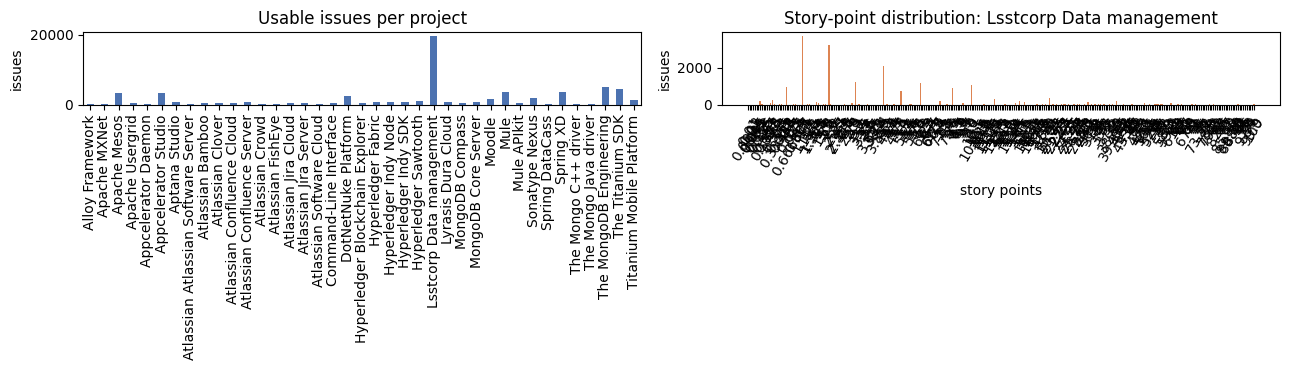

In [4]:
# Why: cleaning decisions (duplicates, outlier cap, name mapping) change the data, so they are executed in the open and their
# counts are printed and stored with the results.
from spsbert.data import build_dataset, clean_text, compose_text, load_raw, project_summary

csv_path = Path(cfg.data.csv_path)
prepare_data(csv_path)           # finds tawos_issues.csv or converts a TAWOS .sql/.zip dump found in data/, /kaggle/input, /content
if not csv_path.exists():
    if IN_COLAB:                                   # convenient upload prompt on Colab
        from google.colab import files
        print(f"{csv_path} not found - please upload your tawos_issues.csv now")
        uploaded = files.upload()
        csv_path.parent.mkdir(parents=True, exist_ok=True)
        csv_path.write_bytes(next(iter(uploaded.values())))
    else:
        raise FileNotFoundError(f"{csv_path} not found. Put the TAWOS download (.sql / .zip / .sql.gz) or tawos_issues.csv into the "
                                "data/ folder (Kaggle: add it as an input dataset). An SQL dump is converted automatically. "
                                "See docs/RUN_GUIDE.md.")

df, clean_report = build_dataset(cfg.data)
print("Cleaning report:")
display(pd.Series(clean_report, name="value").to_frame())
summary = project_summary(df)
display(summary)

DEMO_PROJECT = summary.sort_values("n_issues").iloc[0]["project"]       # smallest usable project -> fast demos
BIGGEST = summary.sort_values("n_issues").iloc[-1]["project"]
print("Demo project:", DEMO_PROJECT)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
summary.set_index("project")["n_issues"].plot(kind="bar", ax=ax[0], color="#4c72b0")
ax[0].set_title("Usable issues per project"); ax[0].set_ylabel("issues"); ax[0].set_xlabel("")
sp = df[df.project == BIGGEST]["story_point"]
vals, cnt = np.unique(sp, return_counts=True)
ax[1].bar(range(len(vals)), cnt, color="#dd8452"); ax[1].set_xticks(range(len(vals))); ax[1].set_xticklabels([f"{v:g}" for v in vals], rotation=60)
ax[1].set_title(f"Story-point distribution: {BIGGEST}")
ax[1].set_xlabel("story points"); ax[1].set_ylabel("issues")
plt.tight_layout(); plt.show()

In [5]:
# Why: a visible before/after example lets a reader check that the cleaning removes noise but keeps the meaning.
# Preprocessing example: raw text versus cleaned model input
raw = load_raw(cfg.data.csv_path)
raw_counts = raw.groupby("project").size().sort_values(ascending=False)
print(f"{len(raw_counts)} projects in the CSV (rows before cleaning). Use these exact names to fix any 'not found' warning above:")
display(raw_counts.head(60).to_frame("rows"))
for _, r in raw[raw.project == DEMO_PROJECT].head(3).iterrows():
    print("RAW  :", (str(r["title"]) + " | " + str(r["description"]))[:260].replace("\n", " "))
    print("CLEAN:", compose_text(clean_text(r["title"]), clean_text(r["description"]))[:260])
    print()

39 projects in the CSV (rows before cleaning). Use these exact names to fix any 'not found' warning above:


,rows
project,
Lsstcorp Data management,20664
The MongoDB Engineering,5402
The Titanium SDK,4665
Mule,4170
Spring XD,3705
Appcelerator Studio,3406
Apache Mesos,3272
DotNetNuke Platform,2594
Sonatype Nexus,1845


RAW  : "Get True value from MXNet Scala NDArray" | """[https://github.com/apache/incubator-mxnet/issues/12679]    With the conversation back and forth, the committers reach to a major vote that I should implement this feature in the right way. And that is what I am g
CLEAN: "Get True value from MXNet Scala NDArray". """[ URL With the conversation back and forth, the committers reach to a major vote that I should implement this feature in the right way. And that is what I am going to do. Corresponding discussion and ongoing PR: UR

RAW  : "Dynamic shape inference" | nan
CLEAN: "Dynamic shape inference"

RAW  : "Support float16 in InstanceNorm operator" | nan
CLEAN: "Support float16 in InstanceNorm operator"



## 3. Random 80:20 split and five-fold cross-validation (guideline §3.2)

**What.** Show, on the smallest project, exactly how the data is divided: 80 % development / 20 % held-out test, and the development part into five folds.

**Why.** The test set is reserved for the final evaluation only (guideline §3.2): it is never used to fit parameters, choose hyper-parameters or stop training. The code *asserts* that development and test sets do not overlap and that every development issue is validated exactly once, so a leak would stop the run instead of passing unnoticed. The same logic runs for every project in Section 6.

**Expected output.** A size table, an empty overlap set, and `True` for full fold coverage.

In [6]:
# Why: the assertions turn a possible data leak into an immediate error; the test set must stay untouched until the final evaluation.
from spsbert.splits import assert_valid_split, make_split

dfp = df[df.project == DEMO_PROJECT].sort_values("issue_key", kind="mergesort").reset_index(drop=True)
split = make_split(len(dfp), cfg.split.test_size, cfg.split.n_folds, cfg.seed)
assert_valid_split(split, len(dfp))
rows = [{"part": "all issues", "issues": len(dfp)},
        {"part": f"development ({1 - cfg.split.test_size:.0%})", "issues": len(split.dev_idx)},
        {"part": f"held-out test ({cfg.split.test_size:.0%})", "issues": len(split.test_idx)}]
for k, (tr, va) in enumerate(split.folds, 1):
    rows.append({"part": f"fold {k}: train / validation", "issues": f"{len(tr)} / {len(va)}"})
display(pd.DataFrame(rows))
print("test ∩ development =", set(split.test_idx.tolist()) & set(split.dev_idx.tolist()), "(must be empty)")
print("Each development issue validates exactly once:", sorted(np.concatenate([va for _, va in split.folds]).tolist()) == sorted(split.dev_idx.tolist()))

,part,issues
0,all issues,204
1,development (80%),163
2,held-out test (20%),41
3,fold 1: train / validation,130 / 33
4,fold 2: train / validation,130 / 33
5,fold 3: train / validation,130 / 33
6,fold 4: train / validation,131 / 32
7,fold 5: train / validation,131 / 32


test ∩ development = set() (must be empty)
Each development issue validates exactly once: True


## 4. SBERT embedding extraction (guideline §3.1)

**What.** Turn every issue text into one 768-number vector with a frozen SBERT model, and show an example of semantic similarity.

**Why frozen?** Most projects have only a few hundred issues; fine-tuning a 110-million-parameter encoder on them would overfit. The encoder never sees the story points, so encoding all issues once, before splitting, leaks no label information. Vectors are cached on disk.

**Is this strictly SBERT?** Yes. SBERT (*Sentence-BERT*; Reimers & Gurevych, 2019) is the method that fine-tunes a transformer in a siamese setup so that a whole text maps to one fixed-size vector; the `sentence-transformers` library implements it. We use the library's recommended general-purpose model, `sentence-transformers/all-mpnet-base-v2` (MPNet backbone, trained contrastively on more than a billion sentence pairs). The assignment asks for "SBERT-based sentence embeddings", not for one backbone, so any `sentence-transformers` model qualifies; the model name is one line in the configuration. For the original BERT-backbone checkpoint of the SBERT paper, use `sentence-transformers/bert-base-nli-mean-tokens` (older and weaker) and re-run.

**Expected output.** The encoder name, the matrix shape `(issues, 768)`, a mean vector length of 1.000 (the vectors are L2-normalised), and the most similar issue to issue 0.

In [7]:
# Why: encode once and cache; the encoder is frozen and never sees story points, so no label information leaks into the split.
from spsbert.embeddings import EmbeddingStore, build_encoder

encoder = build_encoder(cfg.embedding)
store = EmbeddingStore(encoder, cfg.embedding)
emb = store.get(dfp["text"].tolist())
print(f"Encoder: {encoder.name}")
print(f"Embedding matrix: shape={emb.shape}, dtype={emb.dtype}, mean L2 norm={np.linalg.norm(emb, axis=1).mean():.3f}")
E = emb / np.linalg.norm(emb, axis=1, keepdims=True)
sims = E @ E[0]; sims[0] = -np.inf; j = int(sims.argmax())
print(f"\nIssue 0           : {dfp.text[0][:150]}")
print(f"Most similar issue: {dfp.text[j][:150]}   (cosine = {E[0] @ E[j]:.3f})")

01:21:56 | INFO    | Loaded SBERT 'sentence-transformers/all-mpnet-base-v2' on cuda (dim=768, max_seq_length=384)
Encoder: sentence-transformers/all-mpnet-base-v2
Embedding matrix: shape=(204, 768), dtype=float32, mean L2 norm=1.000

Issue 0           : "Get True value from MXNet Scala NDArray". """[ URL With the conversation back and forth, the committers reach to a major vote that I should implement
Most similar issue: "Support NDArray MXNet interface (no default values are supported)"   (cosine = 0.581)


## 5. Prediction component: three-layer CNN, and the baselines (guideline §3.1)

**What.** Build the three-layer CNN and the baselines, and list the hyper-parameter grid.

**Architecture.** The embedding is treated as a one-channel signal and passed through three blocks of *Conv1d → BatchNorm → ReLU → AvgPool*, then *Dropout → Linear → ReLU → Dropout → Linear(1)*. Story points are log-transformed and standardised (they are heavily skewed), the loss is Huber, the optimiser is Adam, and training stops early on a 10 % hold-out taken from the *training part only*. Predictions are clipped to the training range.

**Why baselines?** An MAE value alone does not show whether a model is "effective". The median predictor shows whether the text carries any signal; TF-IDF + Ridge shows whether *semantic* embeddings beat plain word counts; SBERT + Ridge shows whether the CNN's extra capacity pays off.

**Expected output.** The network printout with its parameter count, a table of the five methods, the grid, and the source of the CNN builder.

In [8]:
# Why: printing the architecture and parameter count documents the CNN exactly (guideline §3.1) and shows the capacity relative to the data size.
from spsbert.models import build_cnn_module, build_method_specs

c = cfg.cnn
net = build_cnn_module(emb.shape[1], c.channels, c.kernel_size, c.pool_size, c.adaptive_pool, c.fc_hidden, 0.3, c.pool_type)
print(net)
print("\nTrainable parameters:", sum(p.numel() for p in net.parameters() if p.requires_grad))
specs = build_method_specs(cfg)
display(pd.DataFrame([{"method": s.name, "label": s.label, "features": s.feature, "grid size": len(s.grid), "final seeds": s.seeds}
                      for s in specs.values()]))
print("CNN hyper-parameter grid (selected by 5-fold CV on development data only):", c.grid)
display(Markdown("```python\n" + inspect.getsource(build_cnn_module) + "\n```"))

Net(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
    (8): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
  )
  (pool): Identity()
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=6144, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): 

,method,label,features,grid size,final seeds
0,mean_baseline,Mean,embedding,1,[42]
1,median_baseline,Median,embedding,1,[42]
2,tfidf_ridge,TF-IDF+Ridge,text,3,[42]
3,sbert_ridge,SBERT+Ridge,embedding,4,[42]
4,sbert_cnn,SBERT+CNN,embedding,6,"[42, 43, 44]"


CNN hyper-parameter grid (selected by 5-fold CV on development data only): {'lr': [0.001], 'dropout': [0.1, 0.3, 0.5], 'weight_decay': [0.0001, 0.01]}


```python
def build_cnn_module(in_dim: int, channels: list, kernel_size: int, pool_size: int,
                     adaptive_pool: int, fc_hidden: int, dropout: float, pool_type: str = "max"):
    """Three Conv1d blocks (Conv-BN-ReLU-Pool) over the embedding vector, then an MLP head.

    The 1-D embedding of length D is treated as a one-channel signal of length D. The head sees the
    whole feature map (``adaptive_pool == 0``, default) so no position information is discarded;
    ``adaptive_pool > 0`` adds a global adaptive pooling to that many positions (smaller, lossier).
    """
    torch, nn = _import_torch()
    assert len(channels) == 3, "three-layer CNN required"
    Pool = nn.MaxPool1d if pool_type == "max" else nn.AvgPool1d
    layers: list = []
    c_in, length = 1, in_dim
    for c in channels:
        layers += [nn.Conv1d(c_in, c, kernel_size, padding=kernel_size // 2), nn.BatchNorm1d(c),
                   nn.ReLU(), Pool(pool_size, ceil_mode=True)]
        c_in = c
        length = -(-length // pool_size)          # ceil division, matches ceil_mode=True
    if adaptive_pool and adaptive_pool > 0:
        agg = nn.AdaptiveMaxPool1d(adaptive_pool) if pool_type == "max" else nn.AdaptiveAvgPool1d(adaptive_pool)
        flat = c_in * adaptive_pool
    else:
        agg, flat = nn.Identity(), c_in * length

    class Net(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.features = nn.Sequential(*layers)
            self.pool = agg
            self.head = nn.Sequential(
                nn.Flatten(), nn.Dropout(dropout), nn.Linear(flat, fc_hidden),
                nn.ReLU(), nn.Dropout(dropout), nn.Linear(fc_hidden, 1),
            )

        def forward(self, x):  # x: (B, D)
            return self.head(self.pool(self.features(x.unsqueeze(1)))).squeeze(-1)

    return Net()

```

## 6. Run the experiments (all projects)

**What.** For every project: split → five-fold cross-validation to choose the CNN settings (development data only) → refit on all development data → score the test set once.

**Why this order.** Choosing settings on the validation folds and touching the test set only once is what makes the reported test numbers unbiased (guideline §3.2 and §3.7). Results are cached per project (configuration hash + data hash), so an interrupted run resumes instead of restarting.

**Expected output.** A time estimate for *this* machine, one progress line per project, and the aggregated tables and figures. About 80 minutes on a T4.

In [9]:
# Why: MAX_PROJECTS / BATCH are debugging switches (None = final run); the estimate and the guard avoid starting a run that cannot finish.
from spsbert.aggregate import aggregate
from spsbert.experiment import run_all

MAX_PROJECTS = None   # FINAL RUN: all projects.
# MAX_PROJECTS = 2    # <- quick trial instead: only the 2 smallest projects
BATCH = None          # free-tier session limits: e.g. (0, 10) then (10, 20) ... in separate sessions, merged afterwards (see docs/RUN_GUIDE.md)
ranked = summary.sort_values(["n_issues", "project"]).project.tolist()
only = ranked[BATCH[0]:BATCH[1]] if BATCH else (ranked[:MAX_PROJECTS] if MAX_PROJECTS else None)
n_sel = summary[summary.project.isin(only or ranked)].n_issues.sum()
from itertools import product
sec_per_epoch_1000 = next((r["value"] for r in DOCTOR if r["check"] == "speed benchmark" and r.get("value")), None)
fits = len(list(product(*cfg.cnn.grid.values()))) * cfg.split.n_folds + len(cfg.cnn.final_seeds)     # CNN fits per project
est_h = sec_per_epoch_1000 * 30 * fits * n_sel / 1000 / 3600 if sec_per_epoch_1000 else None          # assumes ~30 epochs per fit
print(f"Selected {len(only or ranked)} of {len(ranked)} projects ({n_sel} issues); {fits} CNN fits per project with {CONFIG_PATH}.")
print(f"Rough CNN time estimate on THIS machine: ~{est_h:.1f} h (assumes ~30 epochs per fit; baselines add little)." if est_h else "No speed estimate available.")
REQUIRE_FAST_MACHINE = True   # stops early when this machine would need more than 6 h (e.g. no GPU); set False to run anyway
if REQUIRE_FAST_MACHINE and est_h and est_h > 6:
    raise RuntimeError(f"Estimated {est_h:.1f} h on this machine. Enable a GPU (Kaggle: Settings > Accelerator > GPU T4 x2) and Run All again, or set REQUIRE_FAST_MACHINE = False.")
if est_h and est_h > 8:
    print("WARNING: this may not fit one session. Enable a GPU, or use BATCH runs + merge, or CONFIG_PATH = 'config/balanced.yaml'.")
results = run_all(cfg, only=only)          # may take long on the full config; safe to re-run after a disconnect
agg = aggregate(cfg.output_dir)
folds, val, test, macro = agg["folds"], agg["val"], agg["test"], agg["macro"]
PRIMARY = "sbert_cnn"
print(f"\nFinished: {len(results)} project(s). Tables and figures are in {cfg.output_dir}/")

Selected 39 of 39 projects (62532 issues); 33 CNN fits per project with config/default.yaml.
Rough CNN time estimate on THIS machine: ~2.3 h (assumes ~30 epochs per fit; baselines add little).
01:22:02 | INFO    | Usable projects (39): ['Alloy Framework', 'Apache MXNet', 'Apache Mesos', 'Apache Usergrid', 'Appcelerator Daemon', 'Appcelerator Studio', 'Aptana Studio', 'Atlassian Atlassian Software Server', 'Atlassian Bamboo', 'Atlassian Clover', 'Atlassian Confluence Cloud', 'Atlassian Confluence Server', 'Atlassian Crowd', 'Atlassian FishEye', 'Atlassian Jira Cloud', 'Atlassian Jira Server', 'Atlassian Software Cloud', 'Command-Line Interface', 'DotNetNuke Platform', 'Hyperledger Blockchain Explorer', 'Hyperledger Fabric', 'Hyperledger Indy Node', 'Hyperledger Indy SDK', 'Hyperledger Sawtooth', 'Lsstcorp Data management', 'Lyrasis Dura Cloud', 'MongoDB Compass', 'MongoDB Core Server', 'Moodle', 'Mule', 'Mule APIkit', 'Sonatype Nexus', 'Spring DataCass', 'Spring XD', 'The Mongo C++ driv

## 7. Five-fold validation results — reported separately from the test results (guideline §3.4)

**What.** The validation results of the selected configuration: every fold, then mean ± standard deviation over the five folds.

**Why separate from the test results.** Validation scores guided the choice of settings, so they are slightly optimistic; the held-out test scores in Section 8 are the unbiased estimate (guideline §3.4).

**Expected output.** A per-fold MAE/MdAE table for SBERT + CNN, mean ± std tables for all methods, and the selected hyper-parameters per project.

In [10]:
# Why: validation results are shown on their own (guideline §3.4); they guided model selection, so they are not the final estimate.
print("SBERT+CNN: validation MAE of every fold")
fm = folds[folds.method == PRIMARY].pivot(index="project", columns="fold", values="mae"); fm.columns = [f"MAE fold {k}" for k in fm.columns]
fd = folds[folds.method == PRIMARY].pivot(index="project", columns="fold", values="mdae"); fd.columns = [f"MdAE fold {k}" for k in fd.columns]
display(pd.concat([fm, fd], axis=1))

pretty = val.assign(MAE=lambda d: d.mae_mean.map("{:.3f}".format) + " ± " + d.mae_std.map("{:.3f}".format),
                    MdAE=lambda d: d.mdae_mean.map("{:.3f}".format) + " ± " + d.mdae_std.map("{:.3f}".format))
print("\nValidation MAE (mean ± std over 5 folds), all methods")
display(pretty.pivot(index="project", columns="label", values="MAE"))
print("Validation MdAE (mean ± std over 5 folds), all methods")
display(pretty.pivot(index="project", columns="label", values="MdAE"))
print("Selected SBERT+CNN hyper-parameters per project")
display(val[val.method == PRIMARY].set_index("project")[["best_params"]])

SBERT+CNN: validation MAE of every fold


,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,MAE fold 5,MdAE fold 1,MdAE fold 2,MdAE fold 3,MdAE fold 4,MdAE fold 5
project,,,,,,,,,,
Alloy Framework,1.190,1.917,1.375,2.145,1.948,1.050,1.202,1.526,1.132,1.356
Apache MXNet,9.079,2.676,4.704,2.177,2.509,2.282,1.610,1.833,1.379,1.663
Apache Mesos,1.219,1.418,1.365,1.413,1.430,0.879,1.014,0.950,0.791,0.965
Apache Usergrid,1.190,0.765,1.041,0.849,0.942,0.548,0.440,0.615,0.531,0.601
Appcelerator Daemon,7.237,4.492,6.358,3.396,4.100,3.790,3.308,2.588,1.847,2.693
Appcelerator Studio,2.015,2.145,2.003,2.318,2.016,1.403,1.791,1.842,1.677,1.730
Aptana Studio,3.947,4.548,4.729,3.309,5.035,2.722,2.256,2.541,2.492,2.268
Atlassian Atlassian Software Server,1.987,2.555,2.675,1.813,2.094,1.461,1.565,1.972,1.186,1.402
Atlassian Bamboo,1.235,1.129,1.253,1.132,1.123,0.729,0.649,0.718,0.794,0.888



Validation MAE (mean ± std over 5 folds), all methods


label,Mean,Median,SBERT+CNN,SBERT+Ridge,TF-IDF+Ridge
project,,,,,
Alloy Framework,1.859 ± 0.370,1.666 ± 0.397,1.715 ± 0.409,1.699 ± 0.410,1.696 ± 0.397
Apache MXNet,5.335 ± 2.619,4.360 ± 2.970,4.229 ± 2.887,4.255 ± 2.998,4.119 ± 2.936
Apache Mesos,1.565 ± 0.046,1.462 ± 0.071,1.369 ± 0.087,1.345 ± 0.083,1.359 ± 0.059
Apache Usergrid,0.881 ± 0.169,0.852 ± 0.143,0.957 ± 0.166,0.917 ± 0.168,0.903 ± 0.147
Appcelerator Daemon,6.281 ± 0.960,5.503 ± 1.801,5.117 ± 1.614,5.142 ± 1.581,5.087 ± 1.269
Appcelerator Studio,2.342 ± 0.083,2.104 ± 0.113,2.100 ± 0.135,2.084 ± 0.120,2.063 ± 0.127
Aptana Studio,4.766 ± 0.784,4.480 ± 0.840,4.313 ± 0.687,4.276 ± 0.620,4.261 ± 0.721
Atlassian Atlassian Software Server,2.418 ± 0.295,2.304 ± 0.379,2.225 ± 0.373,2.110 ± 0.303,2.114 ± 0.279
Atlassian Bamboo,1.292 ± 0.068,1.145 ± 0.072,1.174 ± 0.064,1.091 ± 0.059,1.120 ± 0.055


Validation MdAE (mean ± std over 5 folds), all methods


label,Mean,Median,SBERT+CNN,SBERT+Ridge,TF-IDF+Ridge
project,,,,,
Alloy Framework,1.105 ± 0.069,1.600 ± 0.548,1.253 ± 0.189,1.173 ± 0.148,1.204 ± 0.233
Apache MXNet,3.484 ± 0.306,2.000 ± 0.000,1.753 ± 0.337,1.738 ± 0.528,1.613 ± 0.191
Apache Mesos,1.208 ± 0.036,1.000 ± 0.000,0.920 ± 0.087,0.906 ± 0.042,0.942 ± 0.057
Apache Usergrid,0.244 ± 0.398,0.200 ± 0.447,0.547 ± 0.070,0.467 ± 0.046,0.456 ± 0.071
Appcelerator Daemon,4.813 ± 0.770,3.200 ± 0.447,2.845 ± 0.740,2.824 ± 0.477,2.861 ± 0.466
Appcelerator Studio,2.371 ± 0.049,2.000 ± 0.000,1.689 ± 0.171,1.548 ± 0.085,1.451 ± 0.095
Aptana Studio,3.812 ± 0.339,3.600 ± 0.894,2.456 ± 0.197,2.564 ± 0.291,2.502 ± 0.304
Atlassian Atlassian Software Server,2.105 ± 0.400,1.600 ± 0.548,1.517 ± 0.290,1.422 ± 0.242,1.485 ± 0.270
Atlassian Bamboo,0.810 ± 0.335,1.000 ± 0.000,0.755 ± 0.090,0.690 ± 0.038,0.708 ± 0.032


Selected SBERT+CNN hyper-parameters per project


,best_params
project,
Alloy Framework,"{'lr': 0.001, 'dropout': 0.1, 'weight_decay': 0.01}"
Apache MXNet,"{'lr': 0.001, 'dropout': 0.1, 'weight_decay': 0.01}"
Apache Mesos,"{'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.0001}"
Apache Usergrid,"{'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.01}"
Appcelerator Daemon,"{'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.0001}"
Appcelerator Studio,"{'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.0001}"
Aptana Studio,"{'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.0001}"
Atlassian Atlassian Software Server,"{'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.01}"
Atlassian Bamboo,"{'lr': 0.001, 'dropout': 0.1, 'weight_decay': 0.0001}"


## 8. Final held-out test results (guideline §3.4)

**What.** The test results: MAE and MdAE per project and method, 95 % bootstrap confidence intervals for SBERT + CNN, and the macro average over projects.

**How to read it.** Lower is better. MAE is sensitive to large errors; MdAE shows the typical error. The macro average gives every project the same weight, so one large project cannot dominate.

In [11]:
# Why: the test set was scored exactly once, after the configuration had been chosen; these are the numbers to report.
order = [l for l in ("Mean", "Median", "TF-IDF+Ridge", "SBERT+Ridge", "SBERT+CNN") if l in set(test.label)]
print("Test MAE per project")
display(test.pivot(index="project", columns="label", values="mae")[order])
print("Test MdAE per project")
display(test.pivot(index="project", columns="label", values="mdae")[order])
print("SBERT+CNN test metrics with 95 % bootstrap confidence intervals and seed variability")
display(test[test.method == PRIMARY].set_index("project")[["n_test", "mae", "mae_ci_lo", "mae_ci_hi", "mae_std_seeds",
                                                           "mdae", "mdae_ci_lo", "mdae_ci_hi", "mdae_std_seeds"]])
print("Macro-average over projects (sorted by test MAE) and number of projects where each method is best")
display(macro)

Test MAE per project


label,Mean,Median,TF-IDF+Ridge,SBERT+Ridge,SBERT+CNN
project,,,,,
Alloy Framework,2.128,1.967,1.965,1.961,1.995
Apache MXNet,5.777,4.268,4.212,4.536,4.323
Apache Mesos,1.637,1.546,1.384,1.328,1.408
Apache Usergrid,1.036,1.031,0.956,1.007,1.032
Appcelerator Daemon,6.604,6.224,5.330,5.653,6.087
Appcelerator Studio,2.304,2.074,1.921,1.998,2.009
Aptana Studio,5.226,4.982,4.741,4.794,4.811
Atlassian Atlassian Software Server,1.973,1.846,1.727,1.690,1.836
Atlassian Bamboo,1.272,1.180,1.186,1.199,1.203


Test MdAE per project


label,Mean,Median,TF-IDF+Ridge,SBERT+Ridge,SBERT+CNN
project,,,,,
Alloy Framework,1.087,2.000,1.327,1.330,1.453
Apache MXNet,4.285,2.000,1.336,1.760,1.477
Apache Mesos,1.208,1.000,0.969,0.933,0.920
Apache Usergrid,0.935,1.000,0.558,0.607,0.675
Appcelerator Daemon,5.417,3.000,2.789,3.165,3.258
Appcelerator Studio,2.371,2.000,1.483,1.512,1.498
Aptana Studio,4.416,5.000,2.808,2.853,2.748
Atlassian Atlassian Software Server,1.404,2.000,1.417,1.265,1.534
Atlassian Bamboo,0.646,1.000,0.865,0.921,0.812


SBERT+CNN test metrics with 95 % bootstrap confidence intervals and seed variability


,n_test,mae,mae_ci_lo,mae_ci_hi,mae_std_seeds,mdae,mdae_ci_lo,mdae_ci_hi,mdae_std_seeds
project,,,,,,,,,
Alloy Framework,61,1.995,1.529,2.545,0.070,1.453,1.040,1.842,0.239
Apache MXNet,41,4.323,1.606,9.300,0.178,1.477,1.062,2.080,0.132
Apache Mesos,654,1.408,1.295,1.532,0.015,0.920,0.849,0.988,0.094
Apache Usergrid,97,1.032,0.836,1.254,0.019,0.675,0.373,0.935,0.036
Appcelerator Daemon,49,6.087,4.202,8.584,0.150,3.258,2.858,3.996,0.191
Appcelerator Studio,658,2.009,1.878,2.164,0.014,1.498,1.460,1.600,0.080
Aptana Studio,168,4.811,3.520,6.292,0.120,2.748,2.292,3.363,0.124
Atlassian Atlassian Software Server,65,1.836,1.466,2.243,0.018,1.534,1.303,1.731,0.064
Atlassian Bamboo,103,1.203,0.899,1.606,0.005,0.812,0.656,0.970,0.008


Macro-average over projects (sorted by test MAE) and number of projects where each method is best


,method,label,test_mae,test_mdae,val_mae,val_mae_fold_std,val_mdae,val_mdae_fold_std,projects_lowest_mae,projects_lowest_mdae
0,tfidf_ridge,TF-IDF+Ridge,1.962,1.158,1.999,0.360,1.173,0.161,21,13
1,sbert_ridge,SBERT+Ridge,2.017,1.227,2.028,0.361,1.180,0.148,10,2
2,sbert_cnn,SBERT+CNN,2.063,1.199,2.058,0.364,1.177,0.158,2,10
3,median_baseline,Median,2.165,1.372,2.181,0.384,1.354,0.213,6,11
4,mean_baseline,Mean,2.442,1.913,2.484,0.313,1.919,0.232,0,3


## 9. Comparative table prescribed by the guideline (§3.4)

**What.** The table the assignment prescribes: representation, model configuration, MAE, MdAE.

**Why only the SBERT row is filled.** The BERT and combined rows belong to other problem statements (PS-1 to PS-4 and PS-9 to PS-12). The stored split files allow a paired comparison with those groups on identical partitions.

In [12]:
# Why: this is the table format the assignment prescribes; only the SBERT row is ours.
display(Markdown((Path(cfg.output_dir) / "tables" / "assignment_table.md").read_text(encoding="utf-8")))

| Scope | Evaluation | Representation | Model configuration | MAE | MdAE |
|---|---|---|---|---|---|
| ALL PROJECTS (macro mean) | 5-fold validation (mean ± std over folds) | BERT word embeddings | not part of PS-5 (assigned to other groups) | - | - |
| ALL PROJECTS (macro mean) | 5-fold validation (mean ± std over folds) | SBERT sentence embeddings | sentence-transformers/all-mpnet-base-v2 (frozen, dim=768) + 3-layer CNN channels=[16, 32, 64], kernel=5, avg-pool, loss=huber, Adam; grid={'lr': [0.001], 'dropout': [0.1, 0.3, 0.5], 'weight_decay': [0.0001, 0.01]} selected by 5-fold CV; final seeds=[42, 43, 44] | 2.058 ± 0.364 | 1.177 ± 0.158 |
| ALL PROJECTS (macro mean) | 5-fold validation (mean ± std over folds) | Combined BERT + SBERT embeddings | not part of PS-5 (assigned to other groups) | - | - |
| ALL PROJECTS (macro mean) | Final held-out test | BERT word embeddings | not part of PS-5 (assigned to other groups) | - | - |
| ALL PROJECTS (macro mean) | Final held-out test | SBERT sentence embeddings | sentence-transformers/all-mpnet-base-v2 (frozen, dim=768) + 3-layer CNN channels=[16, 32, 64], kernel=5, avg-pool, loss=huber, Adam; grid={'lr': [0.001], 'dropout': [0.1, 0.3, 0.5], 'weight_decay': [0.0001, 0.01]} selected by 5-fold CV; final seeds=[42, 43, 44] | 2.063 | 1.199 |
| ALL PROJECTS (macro mean) | Final held-out test | Combined BERT + SBERT embeddings | not part of PS-5 (assigned to other groups) | - | - |

## 10. Plots (guideline §3.5)

**What.** Per-project MAE and MdAE (one row per project, one marker per method), the change against the median baseline, the spread of fold-wise validation errors, and predicted versus true story points.

test_mae_per_project


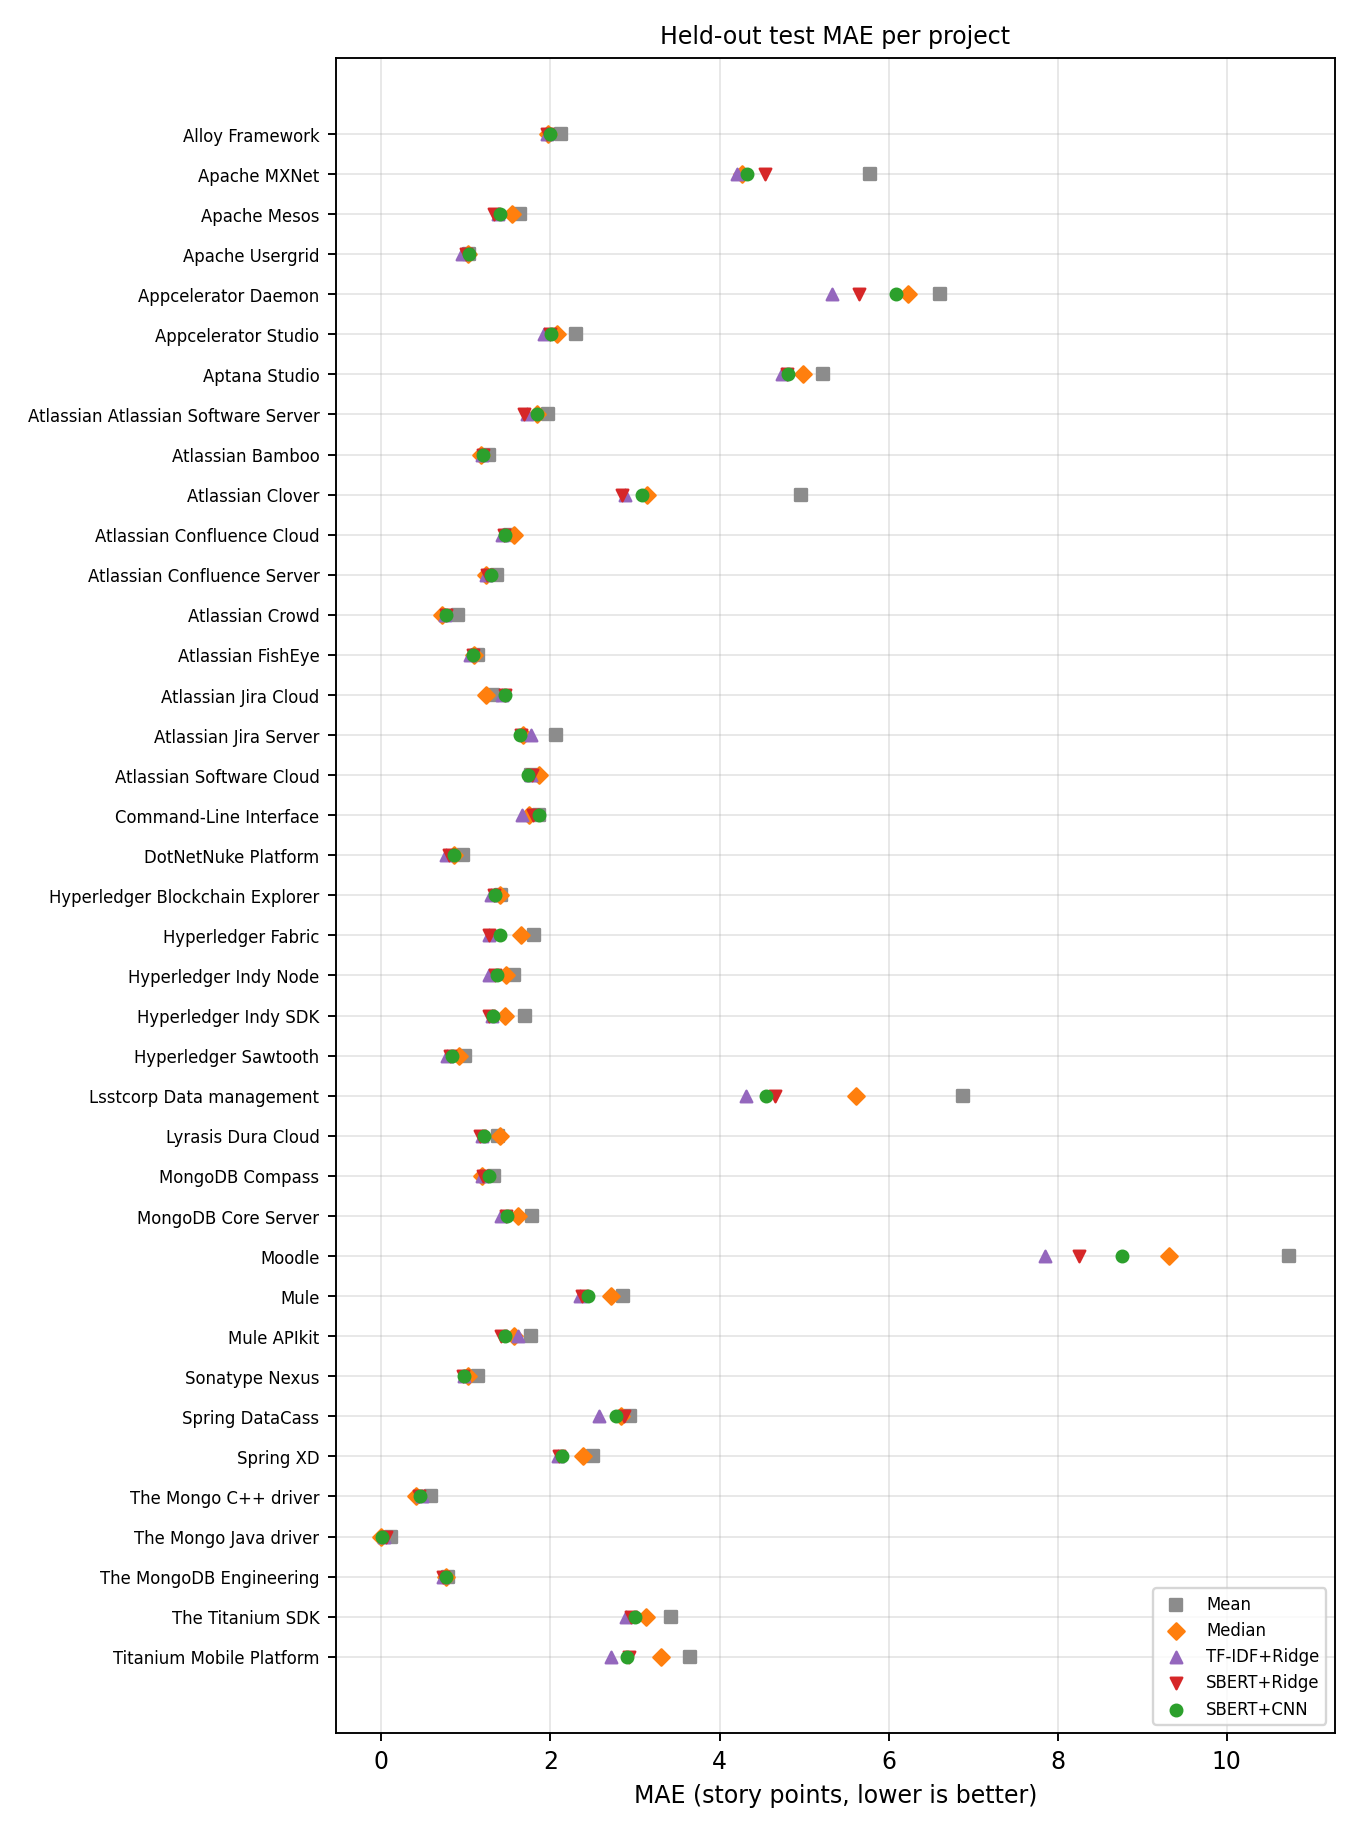

test_mdae_per_project


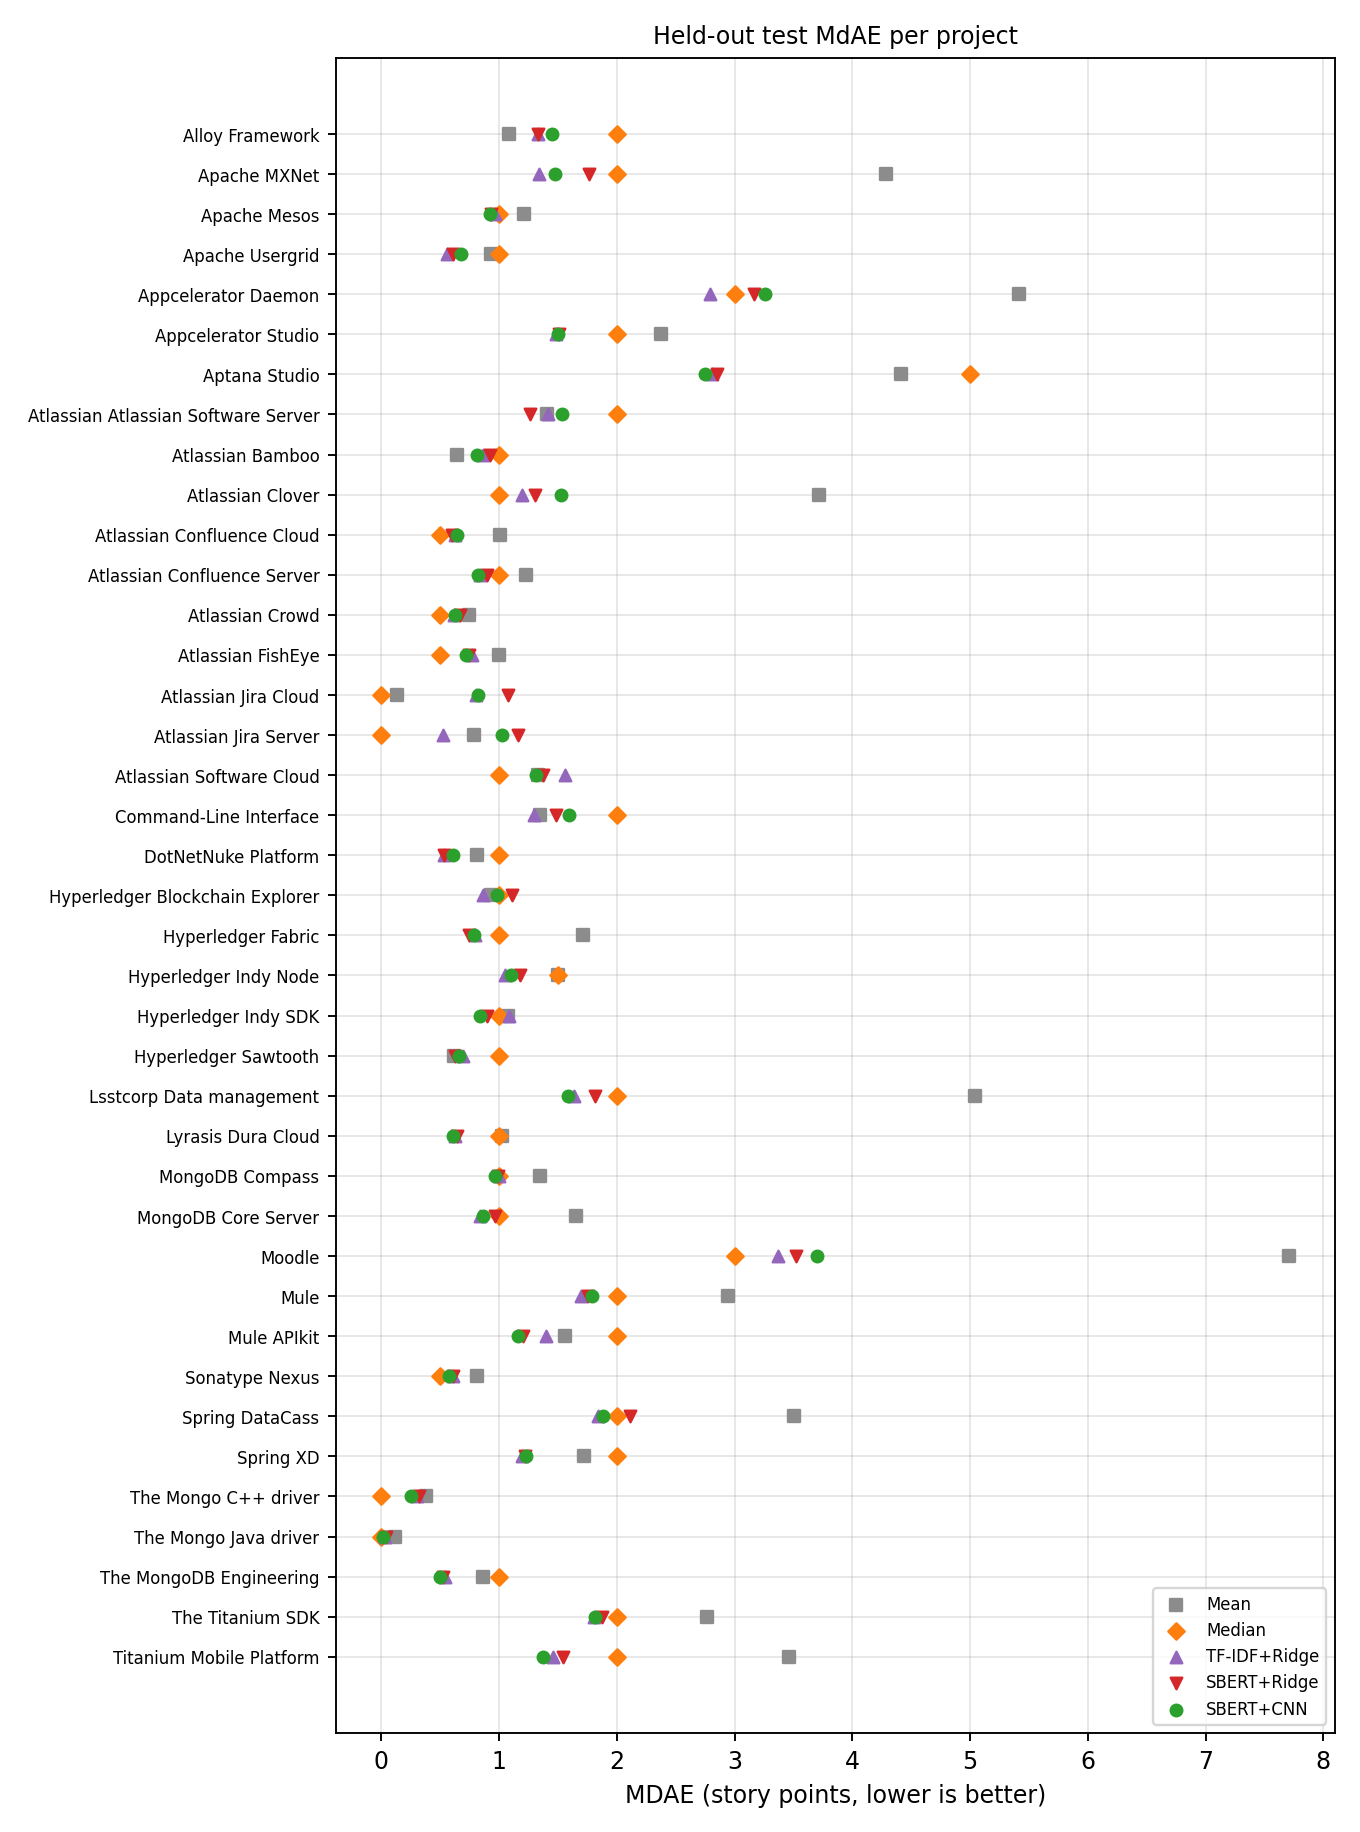

improvement_vs_median


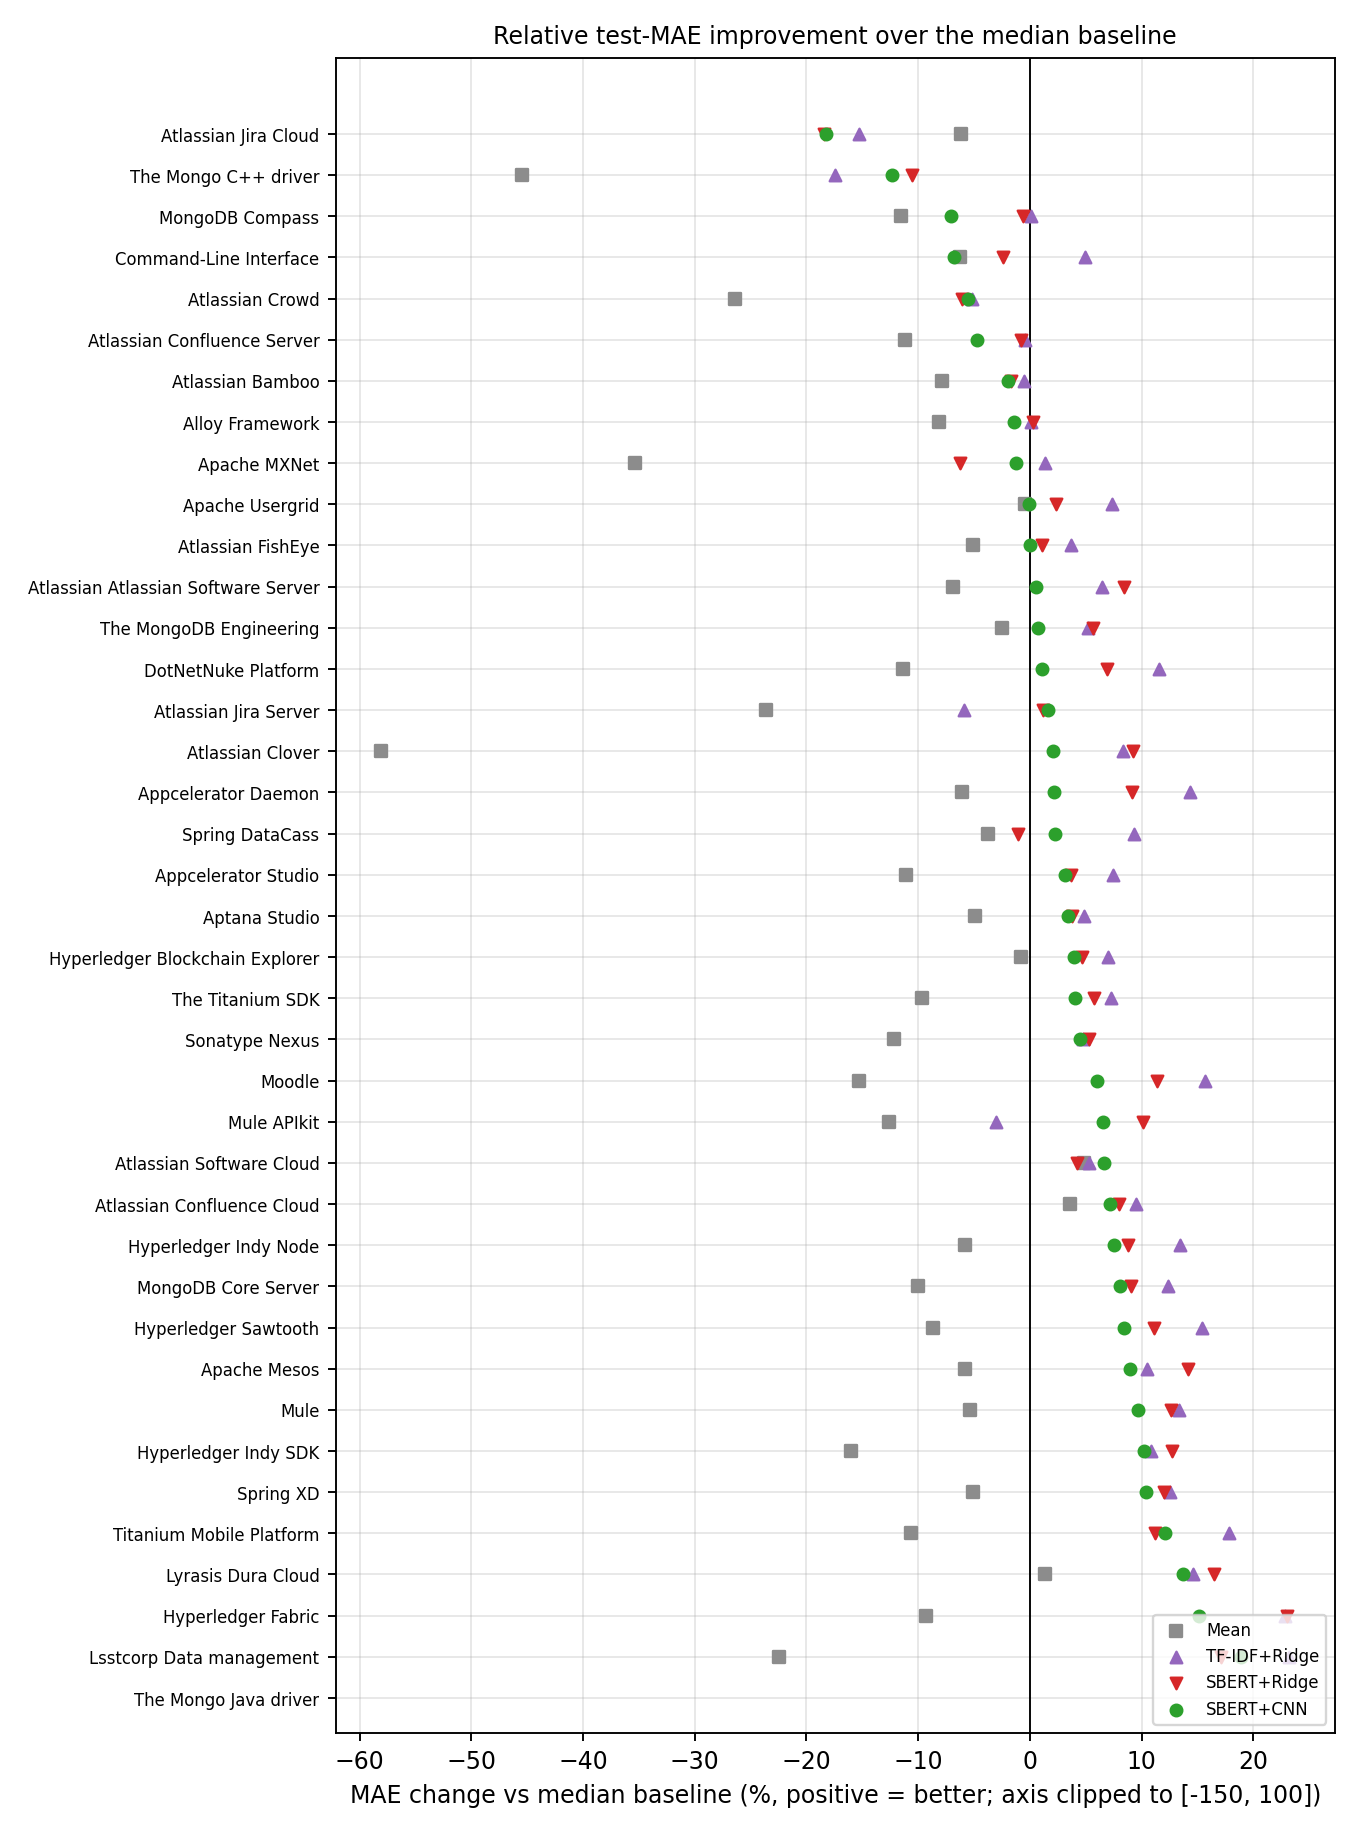

validation_fold_mae_boxplot


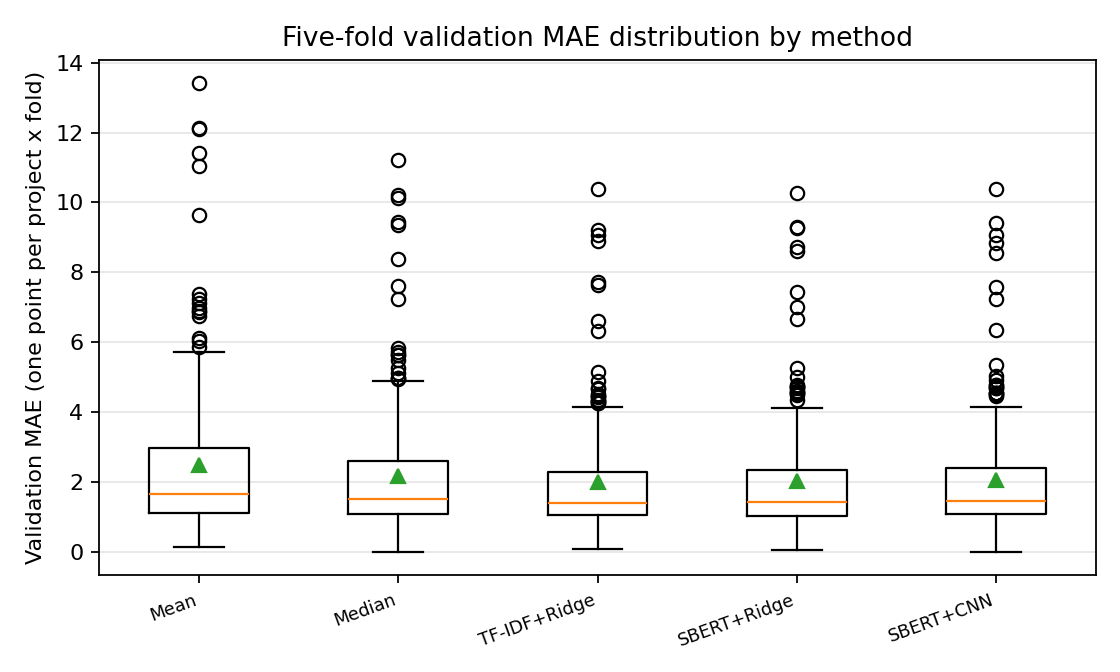

pred_vs_true_pooled


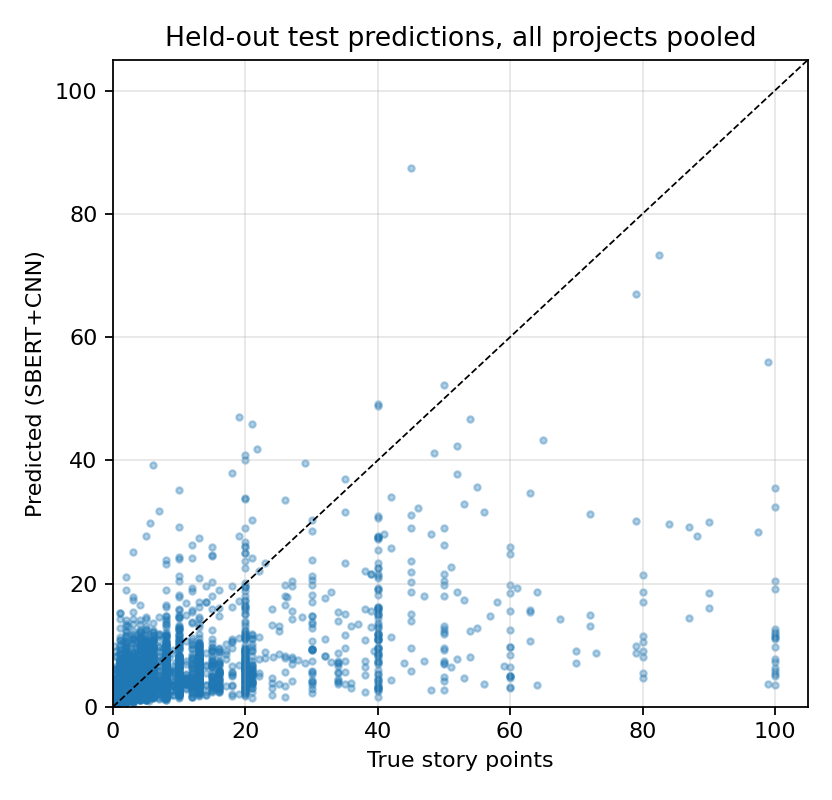

In [13]:
# Why: plots make patterns visible that tables hide (outlier projects, where SBERT wins or loses).
for fn in ("test_mae_per_project", "test_mdae_per_project", "improvement_vs_median", "validation_fold_mae_boxplot", "pred_vs_true_pooled"):
    f = Path(cfg.output_dir) / "figures" / f"{fn}.png"
    if f.exists():
        print(fn); display(Image(filename=str(f)))

## 11. Statistical analysis

**What.** Paired Wilcoxon tests on per-issue errors (raw and Holm-corrected across projects), a cross-project Wilcoxon test, a Friedman rank test over the 39 projects, win/tie/loss counts, and which project properties go with SBERT's gains.

**Why.** A lower average error can be chance. These tests say how much of the difference is systematic. They describe these 39 projects; they are not proof about software projects in general.

In [14]:
# Why: with 39 projects, some p-values fall below 0.05 by chance; the Holm-corrected columns control that.
cols = ["project", "n_test", "p_vs_median", "p_vs_median_holm", "p_vs_tfidf", "p_vs_tfidf_holm"]
display(test[test.method == PRIMARY].set_index("project")[cols[1:]])
print("Cross-project Wilcoxon (SBERT+CNN vs median, per-project test MAE):", agg["cross_project_wilcoxon"])
print("Rank test, win/tie/loss and correlations:", agg["extra"])
imp = agg["improvement"]
if not imp.empty:
    print("\nMAE change vs the median baseline (%, positive = better), macro mean per method:")
    display(imp.groupby("method")[["mae_improvement_pct", "mdae_improvement_pct"]].mean())

,n_test,p_vs_median,p_vs_median_holm,p_vs_tfidf,p_vs_tfidf_holm
project,,,,,
Alloy Framework,61,0.832,1.000,0.917,1.000
Apache MXNet,41,0.908,1.000,0.221,1.000
Apache Mesos,654,0.000,0.000,0.223,1.000
Apache Usergrid,97,0.756,1.000,0.048,1.000
Appcelerator Daemon,49,0.636,1.000,0.004,0.130
Appcelerator Studio,658,0.717,1.000,0.145,1.000
Aptana Studio,168,0.426,1.000,0.303,1.000
Atlassian Atlassian Software Server,65,0.863,1.000,0.116,1.000
Atlassian Bamboo,103,0.333,1.000,0.380,1.000


Cross-project Wilcoxon (SBERT+CNN vs median, per-project test MAE): {'n_projects': 39, 'p_value': 0.0005585208127740771, 'projects_a_better': 28, 'projects_b_better': 11}
Rank test, win/tie/loss and correlations: {'n_projects': 39, 'mean_ranks': {'mean_baseline': 4.794871794871795, 'median_baseline': 3.3333333333333335, 'tfidf_ridge': 1.6666666666666667, 'sbert_ridge': 2.230769230769231, 'sbert_cnn': 2.9743589743589745}, 'friedman': {'chi2': 88.96410256410252, 'p': 2.1853984363463416e-18}, 'primary_vs': {'mean_baseline': {'wins': 37, 'ties': 0, 'losses': 2, 'wilcoxon_p': 9.204086381942034e-10}, 'median_baseline': {'wins': 28, 'ties': 0, 'losses': 11, 'wilcoxon_p': 0.0005585208127740771}, 'tfidf_ridge': {'wins': 5, 'ties': 0, 'losses': 34, 'wilcoxon_p': 4.021188942715526e-06}, 'sbert_ridge': {'wins': 9, 'ties': 0, 'losses': 30, 'wilcoxon_p': 0.0016351219310308807}}, 'improvement_spearman': {'n_issues': {'rho': 0.5526071026490974, 'p': 0.000321225458962696}, 'mode_share': {'rho': -0.2784

,mae_improvement_pct,mdae_improvement_pct
method,,
mean_baseline,-11.369,-37.828
sbert_cnn,3.150,11.972
sbert_ridge,5.306,10.510
tfidf_ridge,6.669,12.944


## 12. Discussion (guideline §3.4)

**What.** The numbers needed to answer the assignment's question: which representation achieves the lowest MAE and MdAE.

**Why computed, not typed.** Every statement is derived from the result tables above, so the text can never claim more than was measured (guideline §3.7: report actual findings, do not claim unsupported improvements).

In [15]:
# Why: the answer to the assignment's discussion question is computed from the tables, never typed by hand.
m = macro.set_index("method")
best_mae, best_mdae = m["test_mae"].idxmin(), m["test_mdae"].idxmin()
print(f"Lowest macro test MAE : {m.loc[best_mae, 'label']} = {m.loc[best_mae, 'test_mae']:.3f}")
print(f"Lowest macro test MdAE: {m.loc[best_mdae, 'label']} = {m.loc[best_mdae, 'test_mdae']:.3f}")
if "median_baseline" in m.index and PRIMARY in m.index:
    gain = 100 * (m.loc["median_baseline", "test_mae"] - m.loc[PRIMARY, "test_mae"]) / m.loc["median_baseline", "test_mae"]
    print(f"SBERT+CNN vs median baseline (macro test MAE): {gain:+.1f} %")
if "sbert_ridge" in m.index and PRIMARY in m.index:
    print(f"SBERT+Ridge {m.loc['sbert_ridge', 'test_mae']:.3f}  vs  SBERT+CNN {m.loc[PRIMARY, 'test_mae']:.3f}  (does the non-linear CNN add value?)")
if "tfidf_ridge" in m.index and "sbert_ridge" in m.index:
    print(f"TF-IDF+Ridge {m.loc['tfidf_ridge', 'test_mae']:.3f}  vs  SBERT+Ridge {m.loc['sbert_ridge', 'test_mae']:.3f}  (semantic vs lexical features)")

Lowest macro test MAE : TF-IDF+Ridge = 1.962
Lowest macro test MdAE: TF-IDF+Ridge = 1.158
SBERT+CNN vs median baseline (macro test MAE): +4.7 %
SBERT+Ridge 2.017  vs  SBERT+CNN 2.063  (does the non-linear CNN add value?)
TF-IDF+Ridge 1.962  vs  SBERT+Ridge 2.017  (semantic vs lexical features)


**Your interpretation — write this in your own words before submitting.** Use the numbers printed above and do not claim more than they show.

- Which method has the lowest MAE and MdAE, and by how much? Is the gap larger than the confidence intervals, and does it survive the Holm correction?
- How does SBERT + CNN compare with the median baseline, with SBERT + Ridge, and with TF-IDF + Ridge? What could explain the order (sample size, a strong constant baseline, team-specific scales)?
- In which projects does SBERT + CNN lose to the median baseline, and what do those projects have in common?

**Limitations and threats to validity.** Random splitting lets the model see issues created after the test issues (temporal leakage), so scores are optimistic compared with real deployment. One random split per project gives noisy estimates for small projects. Only exact duplicate texts are removed. The outlier cap (story points above 100) is a modelling decision the assignment does not specify. Story points are team-specific and noisy. The frozen encoder truncates long texts and is not tuned for effort. The 39 projects are not a random sample of software projects.

## 13. Demonstration and reproducibility check (guideline §3.6)

**What.** (1) Predict the story points of three new issue texts with the model selected for the smallest project. (2) Recompute that whole project from scratch and compare it with the stored results.

**Why.** The guideline asks for a demonstration and for reproducible principal results (§3.6, §3.7). On a CPU the recomputation is bit-identical; on a GPU the tolerance is 0.001.

**Expected output.** A table of predictions and the line `REPRODUCIBLE`.

In [16]:
# Why: the guideline requires a demonstration and reproducible principal results; GPUs may differ in the last floating-point digits.
import torch
from spsbert.demo import predict_texts, verify_project

DEMO_TEXTS = ["Fix typo in the label of the save button",
              "Redesign the plugin architecture and migrate all modules to the new concurrency model",
              "Add a configuration option to disable the weekly report email"]
preds = predict_texts(cfg.output_dir, DEMO_PROJECT, DEMO_TEXTS, csv_path=cfg.data.csv_path)
display(pd.DataFrame({"issue text": DEMO_TEXTS, "predicted story points": preds}))

tol = 1e-3 if torch.cuda.is_available() else 1e-6          # GPUs may differ at floating-point noise level
r = verify_project(cfg.output_dir, DEMO_PROJECT, csv_path=cfg.data.csv_path, tol=tol)
display(pd.DataFrame(r["rows"]))
print("REPRODUCIBLE: recomputation matches the stored results" if r["all_match"] else "NOT REPRODUCED - see mismatches")

02:44:45 | INFO    | Loaded SBERT 'sentence-transformers/all-mpnet-base-v2' on cuda (dim=768, max_seq_length=384)


,issue text,predicted story points
0,Fix typo in the label of the save button,3.298
1,Redesign the plugin architecture and migrate all modules to the new concurrency model,4.312
2,Add a configuration option to disable the weekly report email,3.468


02:44:55 | INFO    | Loaded SBERT 'sentence-transformers/all-mpnet-base-v2' on cuda (dim=768, max_seq_length=384)
02:44:55 | INFO    |   Mean             val MAE 5.335±2.619 | test MAE 5.777 MdAE 4.285
02:44:55 | INFO    |   Median           val MAE 4.360±2.970 | test MAE 4.268 MdAE 2.000
02:44:55 | INFO    |   TF-IDF+Ridge     val MAE 4.119±2.936 | test MAE 4.212 MdAE 1.336
02:44:55 | INFO    |   SBERT+Ridge      val MAE 4.255±2.998 | test MAE 4.536 MdAE 1.760
02:45:10 | INFO    |   SBERT+CNN        val MAE 4.229±2.887 | test MAE 4.323 MdAE 1.477


,method,metric,stored,recomputed,abs_diff,match
0,mean_baseline,mae,5.777,5.777,0.000,True
1,mean_baseline,mdae,4.285,4.285,0.000,True
2,median_baseline,mae,4.268,4.268,0.000,True
3,median_baseline,mdae,2.000,2.000,0.000,True
4,tfidf_ridge,mae,4.212,4.212,0.000,True
5,tfidf_ridge,mdae,1.336,1.336,0.000,True
6,sbert_ridge,mae,4.536,4.536,0.000,True
7,sbert_ridge,mdae,1.760,1.760,0.000,True
8,sbert_cnn,mae,4.323,4.323,0.000,True
9,sbert_cnn,mdae,1.477,1.477,0.000,True


REPRODUCIBLE: recomputation matches the stored results


## 14. Strict audit against the assignment

**What.** An automatic audit of this run and of the repository against `Project_Guidelines.pdf` §3.1–3.7, plus integrity checks (for example, it recomputes MAE from the saved predictions and re-derives the model selection from the cross-validation grid).

**Reading it.** For a valid final submission everything is `PASS` except `A20` (the report), which stays `PENDING` until Section 16 has been run with your GitHub URL. `A21` is a `WARN` if a reduced configuration was used; `A22` is a `WARN` if fewer than all 39 projects were evaluated. Both must be `PASS` for the final run.

In [17]:
# Why: an independent audit catches mistakes (a placeholder link, a partial run, a missing plot) before submission.
from spsbert.check import run_checks

checks = run_checks(cfg.output_dir, ROOT)
display(pd.DataFrame([c.__dict__ for c in checks]).set_index("id"))
n = {s: sum(c.status == s for c in checks) for s in ("PASS", "FAIL", "WARN", "PENDING")}
print("SUMMARY:", n)
if n["FAIL"]:
    print("FAILED:", [c.id for c in checks if c.status == "FAIL"])

,section,requirement,status,detail
id,,,,
A00,3.4,At least one project evaluated,PASS,"39 project(s): Alloy Framework, Apache MXNet, Apache Mesos, Apache Usergrid, Appcelerator Daemon, Appcelerator Studi..."
A01,3.4,MAE and MdAE reported (validation AND test) for every method and project,PASS,problems: []
A02,3.2,Exactly five validation folds per project and method,PASS,problems: []
A03,3.4,Mean and standard deviation of validation metrics across folds present and consistent with the fold values,PASS,problems: []
A04,3.4,Five-fold validation results reported separately from final held-out test results,PASS,tables/validation_*.csv vs tables/test_results.csv
A05,3.2,80:20 development/test split (20 % held out),PASS,problems: []
A06,3.2,Every development issue validates exactly once (5 balanced folds); test set disjoint from development,PASS,problems: []
A07,3.2,Final configuration selected by validation (development) performance only,PASS,problems: []
A08,3.4,Reported test MAE/MdAE can be recomputed from the saved per-issue predictions,PASS,156 deterministic method results recomputed independently; problems: []


SUMMARY: {'PASS': 22, 'FAIL': 0, 'WARN': 0, 'PENDING': 1}


## 15. Package the outputs

**What.** Summarise the warnings of the run and create three files at the top level of `/kaggle/working`:
1. `<results-folder>_upload_<MMDD_HHMM>.zip` — tables, figures, logs and metadata (needed for the report);
2. `<results-folder>_diagnostics_bundle_<MMDD_HHMM>.zip` — warnings, preflight table and logs (for finding problems);
3. `Group7_github_repo_<MMDD_HHMM>.zip` — the ready-to-push GitHub repository (no data, no cache).

**Why time-stamped.** Older files from earlier runs can never be confused with the newest ones. Refresh the Output panel (or open *Save Version → Output*) if the files do not appear.

In [18]:
# Why: time-stamped files cannot be confused with older runs; the third zip is the repository ready to push to GitHub.
import shutil
print(f"Warnings during the run: {len(WARN_LOG)} ({len(set(WARN_LOG))} distinct)")
for w in sorted(set(WARN_LOG))[:15]:
    print(" -", w[:200])
out_dir = Path(cfg.output_dir).resolve()
DEST = Path("/kaggle/working") if Path("/kaggle/working").exists() else out_dir.parent      # Kaggle shows top-level files of /kaggle/working
import datetime
STAMP = datetime.datetime.now().strftime("%m%d_%H%M")      # time stamp: newer files are never confused with older runs
bundle = make_bundle(cfg.output_dir, DEST / f"{out_dir.name}_diagnostics_bundle_{STAMP}.zip", WARN_LOG, DOCTOR)
archive = shutil.make_archive(str(DEST / f"{out_dir.name}_upload_{STAMP}"), "zip", out_dir)
import zipfile
SKIP = {"data", "cache", "__pycache__", ".ipynb_checkpoints", ".virtual_documents"}
github_zip = DEST / f"Group7_github_repo_{STAMP}.zip"      # ready-to-push repository (no data, no cache, no old trial results)
with zipfile.ZipFile(github_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(ROOT.rglob("*")):
        rel = f.relative_to(ROOT)
        if f.is_dir() or SKIP & set(rel.parts) or f.suffix == ".zip" or (rel.parts[0].startswith("results") and rel.parts[0] != out_dir.name):
            continue
        z.write(f, rel.as_posix())
print("\nFILES TO DOWNLOAD (send the first two here; the third is the repository to push to GitHub):")
print("  1.", archive)
print("  2.", bundle)
print("  3.", github_zip)
print("Kaggle: click the refresh icon next to /kaggle/working in the Output panel, or open Save Version > Output tab.")
print("Send ONLY these two (they carry today's date-time). Ignore older zips from earlier runs, e.g. any file with 'quick' in its name.")
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Warnings during the run: 0 (0 distinct)

FILES TO DOWNLOAD (send the first two here; the third is the repository to push to GitHub):
  1. /kaggle/working/results_upload_1025_0245.zip
  2. /kaggle/working/results_diagnostics_bundle_1025_0245.zip
  3. /kaggle/working/Group7_github_repo_1025_0245.zip
Kaggle: click the refresh icon next to /kaggle/working in the Output panel, or open Save Version > Output tab.
Send ONLY these two (they carry today's date-time). Ignore older zips from earlier runs, e.g. any file with 'quick' in its name.


## 16. Final report PDF (do this last)

**What.** Builds `Group7_Final_Report.pdf` from the results of this run: problem, methodology, experiments, tables, figures, statistics, discussion, limitations, conclusions, and the GitHub link on page 1 (guideline §3.6).

**Why last.** The report needs the final numbers and the real repository link on page 1. Create the GitHub repository first, paste its URL below, and run the cell. Then read the discussion and add your own interpretation. The audit (`A20`) rejects a placeholder link.

In [19]:
# Why: the report needs the real repository URL on page 1 (guideline §3.6), and the audit rejects placeholder links.
GITHUB_URL = ""    # e.g. "https://github.com/<user>/<repo>"
if GITHUB_URL.startswith("http"):
    from spsbert.report import build_report
    pdf = build_report(cfg.output_dir, Path(cfg.output_dir) / "Group7_Final_Report.pdf", GITHUB_URL)
    shutil.copy(pdf, DEST / "Group7_Final_Report.pdf")
    print("Report written:", DEST / "Group7_Final_Report.pdf")
else:
    print("Set GITHUB_URL above, then run this cell again to build the final report PDF.")

Set GITHUB_URL above, then run this cell again to build the final report PDF.
